In [141]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from functions import(
    data_report,
    data_report_dpe,
    data_report_dpe_2021,
    rapport_dataframe,
    descriptive_stat,
    categorie_dpe,
    visu_resultat
)

pd.set_option("display.max_rows", 10, "display.max_columns", None)

In [142]:
df = pd.read_csv(
    "table_dvf/full_dvf.csv", sep=None, engine="python"
)  # Lecture du fichier de l'année 2021

df.info()  #  Affichage des valeurs globale du dataframe

<class 'pandas.DataFrame'>
RangeIndex: 168905 entries, 0 to 168904
Data columns (total 40 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id_mutation                   168905 non-null  str    
 1   date_mutation                 168905 non-null  str    
 2   numero_disposition            168905 non-null  int64  
 3   nature_mutation               168905 non-null  str    
 4   valeur_fonciere               168243 non-null  float64
 5   adresse_numero                96866 non-null   float64
 6   adresse_suffixe               7562 non-null    str    
 7   adresse_nom_voie              168454 non-null  str    
 8   adresse_code_voie             168454 non-null  str    
 9   code_postal                   168284 non-null  float64
 10  code_commune                  168905 non-null  int64  
 11  nom_commune                   168905 non-null  str    
 12  code_departement              168905 non-null  int64  


In [143]:
#  Drop des colonnes inutiles :

usefull_cols = [
    "date_mutation",
    "nature_mutation",
    "valeur_fonciere",
    "adresse_numero",
    "adresse_suffixe",
    "adresse_nom_voie",
    "adresse_code_voie",
    "code_postal",
    "nom_commune",
    "code_departement",
    "type_local",
    "surface_reelle_bati",
    "lot1_surface_carrez",
    "nombre_lots",
]

df_clean = df.copy()

for cols in df_clean.columns:
    if cols not in usefull_cols:
        df_clean = df_clean.drop(cols, axis=1)

**Nettoyage des données du dataframe**

In [144]:
#  Création d'un rapport de nettoyage de la donnée

rapport_qualite = data_report(df_clean)  #  Création du rapport de qualité de la donnée
print(rapport_qualite)  #  Affichage du rapport qualité de la donnée 

{'total_lignes': 168905, 'Nombre de ligne en duplicat': np.int64(61473), 'Nombre de ligne en NaN : ': date_mutation               0
nature_mutation             0
valeur_fonciere           662
adresse_numero          72039
adresse_suffixe        161343
                        ...  
code_departement            0
lot1_surface_carrez    154487
nombre_lots                 0
type_local              74044
surface_reelle_bati    112891
Length: 14, dtype: int64, 'Format des dates : ': <StringDtype(storage='python', na_value=nan)>, 'Format des ventes': dtype('float64'), 'Liste des variable de mutation': ['Vente', 'Vente terrain à bâtir', "Vente en l'état futur d'achèvement", 'Echange', 'Adjudication'], 'Liste des types de locaux en vente': ['Dépendance', 'Appartement', nan, 'Maison', 'Local industriel. commercial ou assimilé']}


In [145]:
#  Suppression des doublons :

initial_count = len(
    df_clean
)  #  Calcul de la longueur du dataframe avant la suppresion des doublons

df_clean = df_clean.drop_duplicates(
    keep="first"
)  #  Retrait des doublons en conservant la première apparition

duplicated_remove = initial_count - len(
    df_clean
)  #  Calcul de la quantite de doublons retirés

print(f"Doublons retirés : {duplicated_remove}")  #  Affichage du résultat

Doublons retirés : 61473


In [146]:
#  Normalisation des données du dataframe

cols_normalisation = [
    "adresse_nom_voie",
    "nom_commune",
    "type_local",
    "nature_mutation",
]  #  Liste des colonnes à normaliser

for columns in cols_normalisation:  #  Boucle de normalisation des colonnes
    df_clean[columns] = df_clean[columns].str.strip().str.lower().str.capitalize()

cols_tostr = ["code_postal", "adresse_numero", "adresse_code_voie"]  #  Colonnes à passer au format str

for colu in cols_tostr:
    try:
        df_clean[colu] = df_clean[colu].astype("Int64").astype(str)
    except ValueError as e:
        df_clean[colu] = df_clean[colu].astype(str)

df_clean["date_mutation"] = pd.to_datetime(
    df_clean["date_mutation"]
)  #  Normalisation de la valeur de date

In [147]:
#  Focalisation du dataframe autour des valeurs clées de l'analyse

count_initial = len(df_clean)  #  Calcul de la quantite de données avant la focalisation

df_clean = df_clean.loc[
    (df_clean["type_local"] == "Appartement") | (df_clean["type_local"] == "Maison")
]  #  Focal 1 (type de local)
df_clean = df_clean.loc[df_clean["nature_mutation"] == "Vente"]  #  Focal 2 (type de mutation)

df_clean = df_clean.loc[
    df_clean["nombre_lots"] < 5
]  # Focal 3 (Eviter les ventes en groupes)

remove_data = count_initial - len(df_clean)

print(
    f"La focalisation sur la question nous a fais perdre {remove_data} lignes de donnée sur {count_initial} lignes"
)

La focalisation sur la question nous a fais perdre 65942 lignes de donnée sur 107432 lignes


In [148]:
#  Remplissage des valeurs nulles du dataframe

count_na = len(
    df_clean
)  #  Calcul du nombre de donnée avant le remplissage / suppression des NaN

df_clean["surface_reelle_bati"] = df_clean["surface_reelle_bati"].fillna(
    df_clean["lot1_surface_carrez"]
)  #  Remplissage via les données du Carrez
df_clean = df_clean.dropna(
    subset=["valeur_fonciere"]
)  #  Suppression des NaN dans ce cas particulier
df_clean = df_clean.dropna(
    subset=["adresse_nom_voie"]
)  #  Suppression des NaN dans ce cas particulier

In [149]:
# Enrichissement du dataframe avec des colonnes supplémentaire

df_clean["prix_mcarre"] = (
    df_clean["valeur_fonciere"] / df_clean["surface_reelle_bati"]
)  #  Calcul du prix du metre carre
df_clean["adresse_ban"] = (
    df_clean["adresse_numero"]
    + " "
    + df_clean["adresse_nom_voie"]
    + " "
    + df_clean["code_postal"]
    + " "
    + df_clean["nom_commune"]
)  #  Ajout de l'adresse totale
df_clean["adresse_total"] = df_clean[
    "adresse_ban"
]  # Colonne de verification lors de la fusion avec le DPE
df_clean["adresse_ban"] = (
    df_clean["adresse_ban"].str.lower().str.capitalize()
)  #  Normalisation de la valeur d'adresse pour correspondre à celle du fichier DPE
df_clean["annee_mutation"] = df_clean[
    "date_mutation"
].dt.year  #  Rajout d'une colonne année de la mutation
df_clean["mois_mutation"] = df_clean[
    "date_mutation"
].dt.month  #  Rajout d'une colonne mois de la mutation

In [150]:
useless_cols = [
    "adresse_numero",
    "adresse_suffixe",
    "adresse_nom_voie",
    "adresse_code_voie",
    "lot1_surface_carrez",
]

for cols in df_clean.columns:
    if cols in useless_cols:
        df_clean = df_clean.drop(cols, axis=1)

In [151]:
#  Rapport de nettoyage du dataframe DVF

print("\n ==== Rapport de nettoyage du Dataframe DVF====")
print(f"Taille initiale du dataframe : {len(df)}")
print(f"Taille du dataframe nettoyé : {len(df_clean)}")
print(f"Nombre de lignes supprimées : {len(df) - len(df_clean)}")
print(f"Nombre de doublons restants : {df_clean.duplicated().sum()}")


 ==== Rapport de nettoyage du Dataframe DVF====
Taille initiale du dataframe : 168905
Taille du dataframe nettoyé : 41465
Nombre de lignes supprimées : 127440
Nombre de doublons restants : 111


Les 111 doublons s'expliquent par la suppression des colonnes précédentes, il ne s'agit donc pas de réels doublons mais de variables proches

**Analyse et nettoyage de la base du DPE**

In [152]:
# Analyse du Dataframe contenant les données postérieures à 2021

dpe = pd.read_csv("table_dpe/dpe_26.csv", sep=None, engine="python")

dpe.info()

<class 'pandas.DataFrame'>
RangeIndex: 106584 entries, 0 to 106583
Data columns (total 9 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   adresse_brut            106539 non-null  str    
 1   adresse_ban             106572 non-null  str    
 2   identifiant_ban         106572 non-null  str    
 3   numero_dpe              106584 non-null  str    
 4   date_etablissement_dpe  106584 non-null  str    
 5   code_postal_ban         106584 non-null  int64  
 6   etiquette_dpe           106584 non-null  str    
 7   _score                  0 non-null       float64
 8   numero_voie_ban         86617 non-null   str    
dtypes: float64(1), int64(1), str(7)
memory usage: 7.3 MB


In [153]:
# Analyse de la qualite du dataframe

dpe_clean = dpe.copy()  #  Création d'une copie

rapport_qualite_dpe = data_report_dpe(dpe)  #  Création du rapport
print(rapport_qualite_dpe)  #  Affichage du rapport

{'total_lignes': 106584, 'Nombre de ligne en duplicat': np.int64(0), 'Nombre de ligne en NaN : ': adresse_brut                  45
adresse_ban                   12
identifiant_ban               12
numero_dpe                     0
date_etablissement_dpe         0
code_postal_ban                0
etiquette_dpe                  0
_score                    106584
numero_voie_ban            19967
dtype: int64, 'Format des dates : ': <StringDtype(storage='python', na_value=nan)>, 'Liste des variable de DPE': ['C', 'D', 'E', 'F', 'G', 'B', 'A']}


In [154]:
# Nettoyage des colonnes inutiles

dpe_clean = dpe_clean.drop(
    ["adresse_brut", "_score", "identifiant_ban"], axis=1
)  #  Suppression de ces colonnes inutiles

# Normalisation des données

dpe_clean["adresse_ban"] = (
    dpe_clean["adresse_ban"].str.strip().str.lower().str.capitalize()
)
dpe_clean["date_etablissement_dpe"] = pd.to_datetime(
    dpe_clean["date_etablissement_dpe"]
)

dpe_clean["etiquette_dpe"] = dpe_clean["etiquette_dpe"].str.strip().str.upper()

# Enrichissement du dataframe

dpe_clean["annee_dpe"] = dpe_clean[
    "date_etablissement_dpe"
].dt.year  #  Ajout d'une colonne année d'établissement du DPE
dpe_clean["mois_dpe"] = dpe_clean[
    "date_etablissement_dpe"
].dt.month  #  Ajout d'une colonne mois d'établissement du DPE

# Suppression des valeurs nulles :
initial_count = len(dpe_clean)  #  Calcul du nombre de donnée avant nettoyage
dpe_clean = dpe_clean.dropna(subset=["adresse_ban"])  #  Suppression des adresses nulles
loss_row = initial_count - len(dpe_clean)

print(
    f"Le nettoyage des valeurs nulles a supprimé {loss_row} donnée sur un dataframe initial de {initial_count}"
)

Le nettoyage des valeurs nulles a supprimé 12 donnée sur un dataframe initial de 106584


In [155]:
#  Rapport de nettoyage du dataframe

print("\n ==== Rapport de nettoyage du Dataframe DPE ====")
print(f"Taille initiale du dataframe : {len(dpe)}")
print(f"Taille du dataframe nettoyé : {len(dpe_clean)}")
print(f"Nombre de lignes supprimées : {len(dpe) - len(dpe_clean)}")
print(f"Nombre de doublons restants : {dpe_clean.duplicated().sum()}")


 ==== Rapport de nettoyage du Dataframe DPE ====
Taille initiale du dataframe : 106584
Taille du dataframe nettoyé : 106572
Nombre de lignes supprimées : 12
Nombre de doublons restants : 0


In [156]:
# Données antérieure à 2021

dpe_2021 = pd.read_csv("table_dpe/dpe_bef_2021_26.csv", sep=None, engine="python")

dpe_2021.info()

<class 'pandas.DataFrame'>
RangeIndex: 83596 entries, 0 to 83595
Columns: 131 entries, id to tv018_zone_ete_rclim_dernier_etage
dtypes: float64(49), int64(28), str(54)
memory usage: 83.6 MB


In [157]:
# Etablissement du rapport qualité de la donnée

rapport_qualite_dpe_2021 = data_report_dpe_2021(dpe_2021)  #  Calcul pour les données
print(rapport_qualite_dpe_2021)

{'total_lignes': 83596, 'Nombre de ligne en duplicat': np.int64(0), 'Nombre de ligne en NaN : ': id                                    0
numero_dpe                            0
usr_diagnostiqueur_id                 0
usr_logiciel_id                       0
tr001_modele_dpe_id                   0
                                     ..
tv018_zone_ete_code                   0
tv018_zone_ete_sclim_inf_150          0
tv018_zone_ete_sclim_sup_150          0
tv018_zone_ete_rclim_autres_etages    0
tv018_zone_ete_rclim_dernier_etage    0
Length: 131, dtype: int64, 'Format des dates : ': <StringDtype(storage='python', na_value=nan)>, 'Liste des variable de DPE': ['N', 'D', 'E', 'A', 'C', 'F', 'B', 'G']}


In [158]:
# Création de la base de travail

dpe_2021_clean = dpe_2021.copy()

In [159]:
# Nettoyage des colonnes inutile

keep_cols = [
    "numero_dpe",
    "date_etablissement_dpe",
    "commune",
    "nom_rue",
    "code_postal",
    "classe_consommation_energie",
]  # Ensemble des colonnes à conserver dans le dataframe

for colonnes in dpe_2021_clean.columns:
    if colonnes not in keep_cols:
        dpe_2021_clean = dpe_2021_clean.drop(colonnes, axis=1)

In [160]:
# Normalisation des données
dpe_2021_clean["adresse_ban"] = (
    dpe_2021_clean["nom_rue"]
    + " "
    + dpe_2021_clean["code_postal"]
    + " "
    + dpe_2021_clean["commune"]
)  #  Création de l'adresse ban du fichier précédent
dpe_2021_clean["adresse_ban"] = (
    dpe_2021_clean["adresse_ban"].str.strip().str.lower().str.capitalize()
)
dpe_2021_clean["date_etablissement_dpe"] = pd.to_datetime(
    dpe_2021_clean["date_etablissement_dpe"]
)

dpe_2021_clean["classe_consommation_energie"] = (
    dpe_2021_clean["classe_consommation_energie"].str.strip().str.upper()
)

dpe_2021_clean = dpe_2021_clean.loc[
    dpe_2021_clean["classe_consommation_energie"] != "N"
]  # Suppression de la valeur abberante

# Enrichissement du dataframe

dpe_2021_clean["annee_dpe"] = dpe_2021_clean[
    "date_etablissement_dpe"
].dt.year  #  Ajout d'une colonne année d'établissement du DPE
dpe_2021_clean["mois_dpe"] = dpe_2021_clean[
    "date_etablissement_dpe"
].dt.month  #  Ajout d'une colonne mois d'établissement du DPE

# Changement de noms et réorganisation des colonnes pour correspondre au fichier post 2021

dpe_2021_clean = dpe_2021_clean.rename(
    columns={
        "classe_consommation_energie": "etiquette_dpe",
        "code_postal": "code_postal_ban",
        "nom_rue": "numero_voie_ban",
        "commune": "commune_ban",
    }
)

ORDER = [
    "adresse_ban",
    "numero_dpe",
    "date_etablissement_dpe",
    "code_postal_ban",
    "etiquette_dpe",
    "numero_voie_ban",
    "annee_dpe",
    "mois_dpe",
]  # Liste de l'ordre des colonnes

dpe_2021_clean = dpe_2021_clean[ORDER]  #  Application de l'ordre

# Suppression des valeurs nulles :
initial_count = len(dpe_2021_clean)  #  Calcul du nombre de donnée avant nettoyage
dpe_2021_clean = dpe_2021_clean.dropna(
    subset=["adresse_ban"]
)  #  Suppression des adresses nulles
loss_row = initial_count - len(dpe_2021_clean)

print(
    f"Le nettoyage des valeurs nulles a supprimé {loss_row} donnée sur un dataframe initial de {initial_count}"
)

#  Création du fichier global du DPE

dpe_full = pd.concat([dpe_clean, dpe_2021_clean])

Le nettoyage des valeurs nulles a supprimé 51 donnée sur un dataframe initial de 69247


In [161]:
#  Rapport de nettoyage du dataframe

print("\n ==== Rapport de nettoyage du Dataframe DPE_2021 ====")
print(f"Taille initiale du dataframe : {len(dpe_2021)}")
print(f"Taille du dataframe nettoyé : {len(dpe_2021_clean)}")
print(f"Nombre de lignes supprimées : {len(dpe_2021) - len(dpe_2021_clean)}")
print(f"Nombre de doublons restants : {dpe_2021_clean.duplicated().sum()}")


 ==== Rapport de nettoyage du Dataframe DPE_2021 ====
Taille initiale du dataframe : 83596
Taille du dataframe nettoyé : 69196
Nombre de lignes supprimées : 14400
Nombre de doublons restants : 0


**Croisement des deux bases de données nettoyées**

In [162]:
#  Fusion des deux bases de données nettoyées

size_dvf = len(df_clean)  #  Calcul de la taille avant fusion
size_dpe = len(dpe_full)

dpe_tri = dpe_full.sort_values("date_etablissement_dpe").reset_index(drop=True)

dvf_tri = df_clean.sort_values("date_mutation").reset_index(drop=True)

dvf_dpe = pd.merge_asof(
    left=dvf_tri,
    right=dpe_tri,
    left_on="date_mutation",
    right_on="date_etablissement_dpe",
    by="adresse_ban",
    direction="backward",
    tolerance=pd.Timedelta(days=3650),
)

dvf_dpe = dvf_dpe.dropna(subset=["etiquette_dpe"])

loose_dvf = size_dvf - len(dvf_dpe)  #  Calcul des pertes pour le DVF
loose_dpe = size_dpe - len(dvf_dpe)  #  Calcul des pertes pour le DPE

print("\n === Rapport Post Fusion des Dataframe ===")
print(f"La fusion a fait perdre {loose_dvf} ligne de DVF et {loose_dpe} lignes de DPE")
print(f"Une perte de {round((loose_dvf / size_dvf ),3) * 100}% de donnée du DVF")
print(f"Et une perte de {round((loose_dpe / size_dpe),3) * 100}% de donnée du DPE")
print(f"Finalement le dataframe mesure {len(dvf_dpe)} lignes")


 === Rapport Post Fusion des Dataframe ===
La fusion a fait perdre 33258 ligne de DVF et 167561 lignes de DPE
Une perte de 80.2% de donnée du DVF
Et une perte de 95.3% de donnée du DPE
Finalement le dataframe mesure 8207 lignes


**ANALYSE EXPLORATOIRE DU DATAFRAME**

In [163]:
# Séparation des dataframes par modalité

dvf_dpe_appartement = dvf_dpe.loc[dvf_dpe["type_local"] == "Appartement"]

dvf_dpe_maison = dvf_dpe.loc[dvf_dpe["type_local"] == "Maison"]

In [164]:
# Analyse global du dataframe pour identifier des valeurs mal encodées

rapport_appartement = rapport_dataframe(dvf_dpe_appartement)
rapport_maison = rapport_dataframe(dvf_dpe_maison)

print("\n === RAPPORT DES VARIABLES DES APPARTEMENTS ===")
print(rapport_appartement)
print(" ")

print("\n === RAPPORT DES VARIABLES DES MAISONS ===")
print(rapport_appartement)


 === RAPPORT DES VARIABLES DES APPARTEMENTS ===
{'Description pour le prix du m² : ': count      5089.000000
mean       3112.774012
std       11348.475260
min           0.020000
25%        1566.666667
50%        2000.000000
75%        2661.111111
max      359704.545455
Name: prix_mcarre, dtype: float64, 'Description pour les étiquettes DPE': count     5089
unique       7
top          D
freq      1889
Name: etiquette_dpe, dtype: object}
 

 === RAPPORT DES VARIABLES DES MAISONS ===
{'Description pour le prix du m² : ': count      5089.000000
mean       3112.774012
std       11348.475260
min           0.020000
25%        1566.666667
50%        2000.000000
75%        2661.111111
max      359704.545455
Name: prix_mcarre, dtype: float64, 'Description pour les étiquettes DPE': count     5089
unique       7
top          D
freq      1889
Name: etiquette_dpe, dtype: object}


**LES DEUX DATAFRAMES POSSEDENT DES VALEURS MAX ET MINIMALES AUX DESSUS DES DONNEES CONNUES POUR LA DRÔME**

Je vais donc appliquer un filtre global sur le dataframe

In [165]:
# Filtrage des données hors contexte

appartement_before = len(dvf_dpe_appartement)  # Calcul de la taille initiale du df
maison_before = len(dvf_dpe_maison)  # Calcul de la taille initiale du df

dvf_dpe_appartement = dvf_dpe_appartement.loc[
    (
        (dvf_dpe_appartement.prix_mcarre >= 1129)  #  Retrait des valeurs inférieurs au prix minimal en Drôme
        & (dvf_dpe_appartement.prix_mcarre <= 3405)  #  Retrait des valeurs supérieures au prix maximal en Drôme
    )
]  #  Filtre pour les appartements
dvf_dpe_maison = dvf_dpe_maison.loc[
    ((dvf_dpe_maison.prix_mcarre >= 1088) & (dvf_dpe_maison.prix_mcarre <= 4687)) #  Retrait des valeurs inférieurs et supérieur au prix minimal en Drôme
]  #  Filtre pour les maison

loose_appartement = appartement_before - len(
    dvf_dpe_appartement
)  #  Calcul des lignes perdues
loose_maison = maison_before - len(dvf_dpe_maison)  #  Calcul des lignes perdues

print("\n === RAPPORT DE PERTE SUITE AUX FILTRE ===")
print(
    f"Les données relatives aux appartements ont perdue {loose_appartement} lignes soit un jeu de donnée de {len(dvf_dpe_appartement)}"
)
print(
    f"Les données relatives aux maisons ont perdue {loose_maison} lignes soit un jeu de donnée de {len(dvf_dpe_maison)}"
)


 === RAPPORT DE PERTE SUITE AUX FILTRE ===
Les données relatives aux appartements ont perdue 1119 lignes soit un jeu de donnée de 3970
Les données relatives aux maisons ont perdue 193 lignes soit un jeu de donnée de 2925


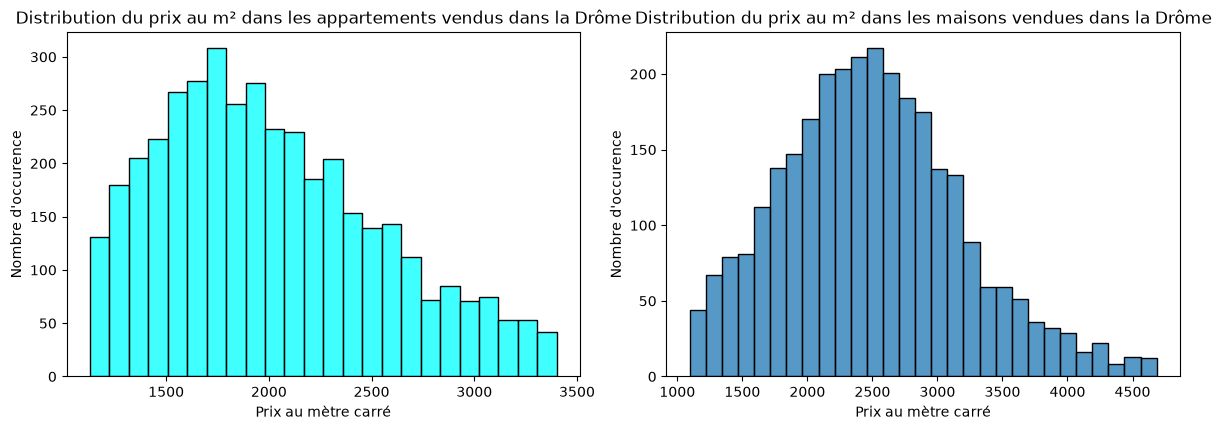

In [166]:
#  Analyse de la distribution de la variables prixmcarre

plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
sns.histplot(dvf_dpe_appartement["prix_mcarre"], color="cyan")
plt.title("Distribution du prix au m² dans les appartements vendus dans la Drôme")
plt.xlabel("Prix au mètre carré")
plt.ylabel("Nombre d'occurence")
plt.tight_layout()
plt.subplot(2, 2, 2)
sns.histplot(dvf_dpe_maison["prix_mcarre"])
plt.title("Distribution du prix au m² dans les maisons vendues dans la Drôme")
plt.xlabel("Prix au mètre carré")
plt.ylabel("Nombre d'occurence")
plt.tight_layout()

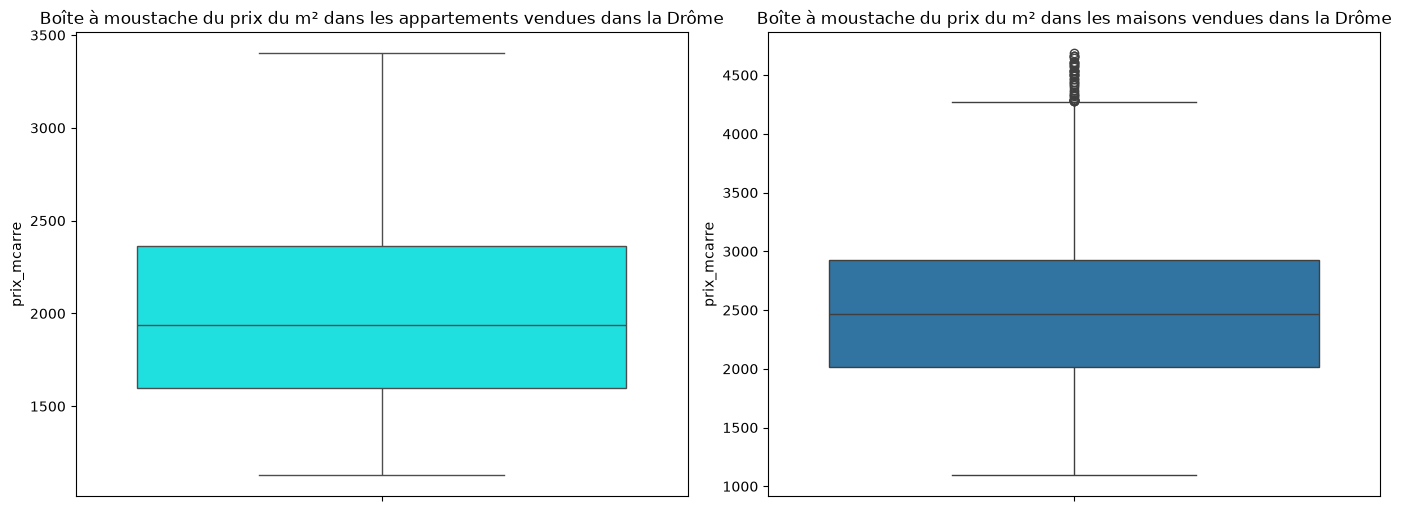

In [167]:
# Analyse de la présence de valeurs outliers

plt.figure(figsize=(14, 10))
plt.subplot(2, 2, 1)
sns.boxplot(dvf_dpe_appartement["prix_mcarre"], color="cyan")
plt.title("Boîte à moustache du prix du m² dans les appartements vendues dans la Drôme")
plt.tight_layout()
plt.subplot(2, 2, 2)
sns.boxplot(dvf_dpe_maison["prix_mcarre"])
plt.title("Boîte à moustache du prix du m² dans les maisons vendues dans la Drôme")
plt.tight_layout()

**PRESENCE DE VALEURS ABBERANTES DANS LE PRIX DES MAISONS**

Le calcul statistique sera adapté pour convenir à cette problématique (médiane)

In [168]:
#  Statistiques

stat_appartement = descriptive_stat(
    dvf_dpe_appartement, "prix_mcarre", "etiquette_dpe"
)  #  Calcul pour les appartement
stat_maison = descriptive_stat(
    dvf_dpe_maison, "prix_mcarre", "etiquette_dpe"
)  #  Calcul pour les maisons

print("\n === STATISTIQUES DESCRIPTIVE DES APPARTEMENTS ===")
print(" ")
print(stat_appartement)
print(" ")
print("\n === STATISTIQUES DESCRIPTIVE DES MAISONS ===")
print(" ")
print(stat_maison)


 === STATISTIQUES DESCRIPTIVE DES APPARTEMENTS ===
 
{'Médiane prix_mcarre : ': np.float64(1935.483870967742), 'Ecart Type prix_mcarre': np.float64(535.9902357461227), 'Q1 de prix_mcarre': np.float64(1600.0), 'Q3 de prix_mcarre': np.float64(2362.316053511706), 'Valeur maximale de prix_mcarre': np.float64(3401.8691588785045), 'Valeur minimale de prix_mcarre': np.float64(1129.032258064516), "Nombre d'occurence de etiquette_dpe": etiquette_dpe
D    1489
C    1170
E     912
F     194
B     133
G      51
A      21
Name: count, dtype: int64}
 

 === STATISTIQUES DESCRIPTIVE DES MAISONS ===
 
{'Médiane prix_mcarre : ': np.float64(2466.019417475728), 'Ecart Type prix_mcarre': np.float64(694.9059133763852), 'Q1 de prix_mcarre': np.float64(2019.6875), 'Q3 de prix_mcarre': np.float64(2923.076923076923), 'Valeur maximale de prix_mcarre': np.float64(4685.714285714285), 'Valeur minimale de prix_mcarre': np.float64(1095.7446808510638), "Nombre d'occurence de etiquette_dpe": etiquette_dpe
C    889
D 

In [169]:
#  Enrichissement du dataframe

dvf_dpe_appartement["categorie_dpe"] = dvf_dpe_appartement.apply(
    categorie_dpe, axis=1
)  #  Ajout de la catégorie pour les appartements
dvf_dpe_maison["categorie_dpe"] = dvf_dpe_maison.apply(
    categorie_dpe, axis=1
)  #  Ajout de la catégorie pour les maisons

#  Analyse des tailles d'effectifs

taille_appartement = dvf_dpe_appartement["categorie_dpe"].value_counts()
taille_maison = dvf_dpe_maison["categorie_dpe"].value_counts()

print("\n === TAILLE EFFECTIFS CATEGORIE DPE APPARTEMENTS ===")
print("")
print(taille_appartement)
print("")
print("\n === TAILLE EFFECTIFS CATEGORIE DPE MAISONS ===")
print("")
print(taille_maison)


 === TAILLE EFFECTIFS CATEGORIE DPE APPARTEMENTS ===

categorie_dpe
Logement performant     3725
Passoire energetique     245
Name: count, dtype: int64


 === TAILLE EFFECTIFS CATEGORIE DPE MAISONS ===

categorie_dpe
Logement performant     2576
Passoire energetique     349
Name: count, dtype: int64


**FIN DE LA PHASE EXPLORATOIRE DE L'ANALYSE**

Nous avons obtenus des données sur la constitution du dataframe ainsi qu'enrichie le nouveau dataframe fusionné

**PHASE D'ANALYSE DE LA VARIABLE CLEE**

In [170]:
# Calcul des prix médians en fonction de l'étiquette DPE et de la catégorie énergétique

median_etiquette_appartement = (
    dvf_dpe_appartement.groupby("etiquette_dpe").prix_mcarre.median().sort_index()
)  #  Caclul pour les appartements
median_etiquette_maison = (
    dvf_dpe_maison.groupby("etiquette_dpe").prix_mcarre.median().sort_index()
)  #  Calcul pour les maisons

median_categorie_appartement = (
    dvf_dpe_appartement.groupby("categorie_dpe").prix_mcarre.median().sort_index()
)  #  Calcul pour les appartements
median_categorie_maison = (
    dvf_dpe_maison.groupby("categorie_dpe").prix_mcarre.median().sort_index()
)  #  Calcul pour les maisons

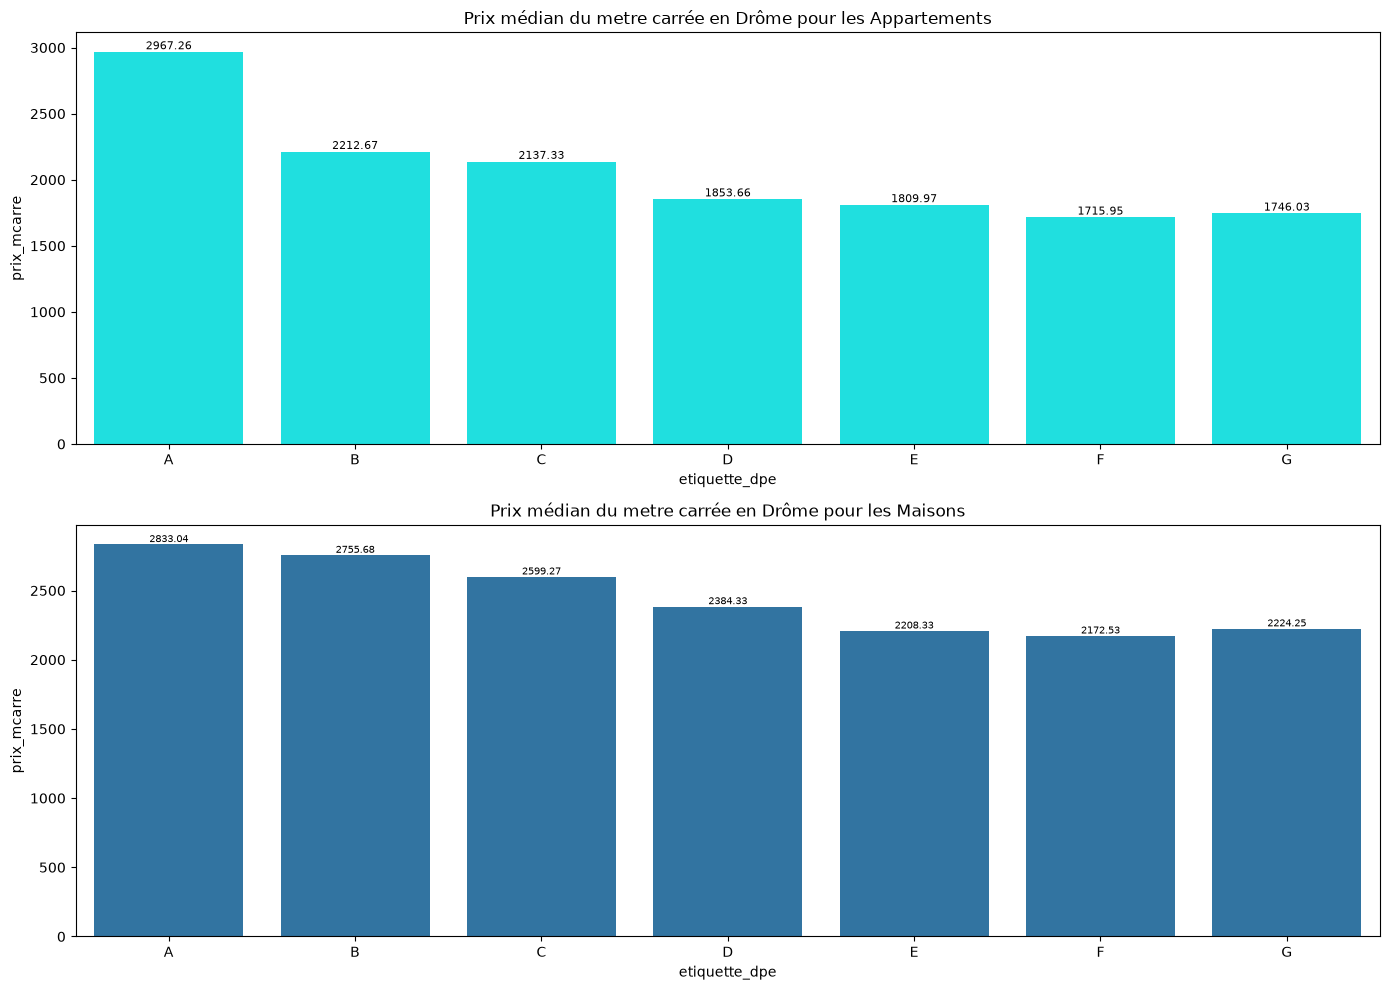

In [171]:
# Visualisation graphique des résultats

visu_resultat(
    median_etiquette_appartement, median_etiquette_maison, "Appartements", "Maisons"
)  #  Affichage du graphique pour les étiquettes_DPE

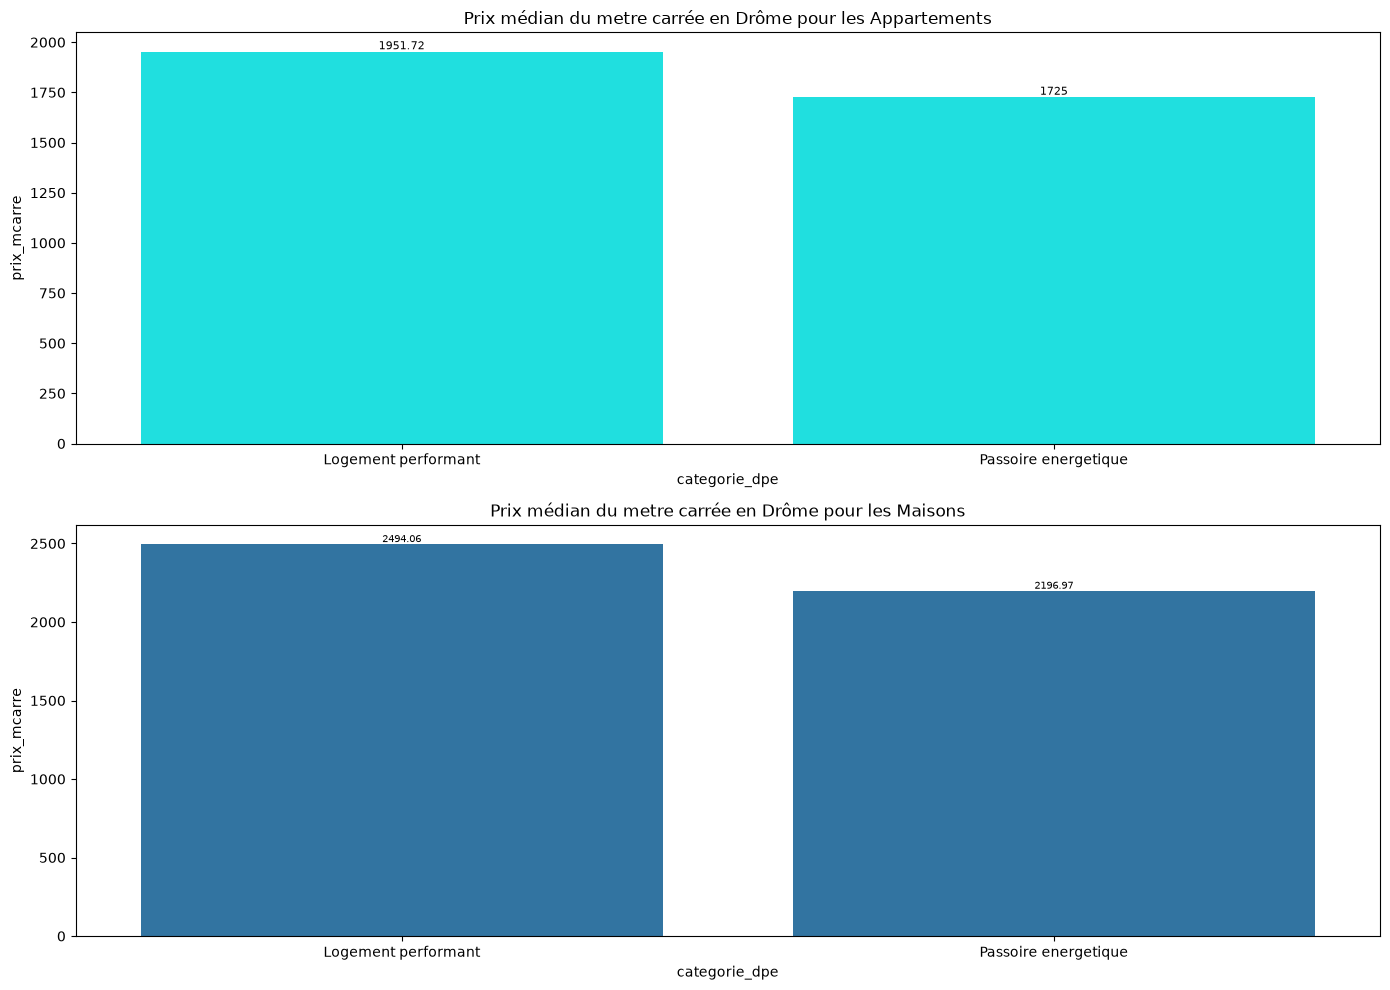

In [172]:
visu_resultat(
    median_categorie_appartement, median_categorie_maison, "Appartements", "Maisons"
)

In [173]:
# Calcul des différences par étiquettes

ecart_vs_a_appartement = (
    median_etiquette_appartement["A"] - median_etiquette_appartement
)  #  Différence des étiquettes par rapport à A pour les appartements
ecart_vs_a_appartement_pct = (
    (median_etiquette_appartement["A"] - median_etiquette_appartement)
    / median_etiquette_appartement["A"]
    * 100
)  # Caclul du pourcentage par rapport à A

ecart_vs_a_maison = (
    median_etiquette_maison["A"] - median_etiquette_maison
)  #  Différence des étiquettes par rapport à A
ecart_vs_a_maisons_pct = (
    (median_etiquette_maison["A"] - median_etiquette_maison)
    / median_etiquette_maison["A"]
    * 100
)

ecart_vs_passoire_appartement = (
    median_categorie_appartement["Logement performant"] - median_categorie_appartement
)
ecart_vs_passoire_appartement_pct = (
    (median_categorie_appartement["Logement performant"] - median_categorie_appartement)
    / median_categorie_appartement["Logement performant"]
    * 100
)  # Caclul du pourcentage par rapport à A

ecart_vs_passoire_maison = (
    median_categorie_maison["Logement performant"] - median_categorie_maison
)
ecart_vs_passoire_maison_pct = (
    (median_categorie_maison["Logement performant"] - median_categorie_maison)
    / median_categorie_maison["Logement performant"]
    * 100
)  # Caclul du pourcentage par rapport à A

print("\n === EVOLUTION DU PRIX DU m² VS ETIQUETTE A ===")
print(
    f"Evolutions du prix du m² en comparaison avec A pour les appartements : {ecart_vs_a_appartement}"
)
print("---")
print(f"Soit une évolution en pourcentage de : {ecart_vs_a_appartement_pct}")
print(" ")
print(
    f"Evolutions du prix du m² en comparaison avec A pour les maisons : {ecart_vs_a_maison}"
)
print("---")
print(f"Soit une évolution en pourcentage de : {ecart_vs_a_maisons_pct}")
print("")
print("")
print("\n === EVOLUTION DU PRIX DU m² VS LOGEMENT PERFORMANT ===")
print(
    f"Evolutions du prix du m² en comparaison avec un logement performant pour les appartements : {ecart_vs_passoire_appartement}"
)
print("---")
print(f"Soit une évolution en pourcentage de : {ecart_vs_passoire_appartement_pct}")
print("")
print(
    f"Evolutions du prix du m² en comparaison avec un logement performant pour les appartements : {ecart_vs_passoire_maison}"
)
print("---")
print(f"Soit une évolution en pourcentage de : {ecart_vs_passoire_maison_pct}")


 === EVOLUTION DU PRIX DU m² VS ETIQUETTE A ===
Evolutions du prix du m² en comparaison avec A pour les appartements : etiquette_dpe
A       0.000000
B     754.589744
C     829.930021
D    1113.597874
E    1157.289476
F    1251.308134
G    1221.224664
Name: prix_mcarre, dtype: float64
---
Soit une évolution en pourcentage de : etiquette_dpe
A     0.000000
B    25.430554
C    27.969609
D    37.529546
E    39.002004
F    42.170543
G    41.156695
Name: prix_mcarre, dtype: float64
 
Evolutions du prix du m² en comparaison avec A pour les maisons : etiquette_dpe
A      0.000000
B     77.358629
C    233.772767
D    448.716629
E    624.709507
F    660.509395
G    608.796265
Name: prix_mcarre, dtype: float64
---
Soit une évolution en pourcentage de : etiquette_dpe
A     0.000000
B     2.730585
C     8.251650
D    15.838681
E    22.050832
F    23.314487
G    21.489130
Name: prix_mcarre, dtype: float64



 === EVOLUTION DU PRIX DU m² VS LOGEMENT PERFORMANT ===
Evolutions du prix du m² en compar

In [174]:
# Analyse des variations tout biens confondus

dvf_dpe_global = pd.concat([dvf_dpe_maison, dvf_dpe_appartement])

median_etiquette_global = (
    dvf_dpe_global.groupby("etiquette_dpe").prix_mcarre.median().sort_index()
)
median_categorie_global = (
    dvf_dpe_global.groupby("categorie_dpe").prix_mcarre.median().sort_index()
)

ecart_vs_a_global = (
    median_etiquette_global["A"] - median_etiquette_global
)  #  Différence des étiquettes par rapport à A
ecart_vs_a_global_pct = (
    (median_etiquette_global["A"] - median_etiquette_global)
    / median_etiquette_global["A"]
    * 100
)

ecart_vs_passoire_global = (
    median_categorie_global["Logement performant"] - median_categorie_global
)
ecart_vs_passoire_global_pct = (
    (median_categorie_global["Logement performant"] - median_categorie_global)
    / median_categorie_global["Logement performant"]
    * 100
)  # Caclul du pourcentage par rapport à A

print("\n === EVOLUTION DU PRIX DU m² VS ETIQUETTE A ===")
print(
    f"Evolutions du prix du m² en comparaison avec A tout type de biens confondus : {ecart_vs_a_global}"
)
print("---")
print(f"Soit une évolution en pourcentage de : {ecart_vs_a_global_pct}")
print("")
print("\n === EVOLUTION DU PRIX DU m² VS LOGEMENT PERFORMANT ===")
print(
    f"Evolutions du prix du m² en comparaison avec un logement performant tout type de biens confondus : {ecart_vs_passoire_global}"
)
print("---")
print(f"Soit une évolution en pourcentage de : {ecart_vs_passoire_global_pct}")


 === EVOLUTION DU PRIX DU m² VS ETIQUETTE A ===
Evolutions du prix du m² en comparaison avec A tout type de biens confondus : etiquette_dpe
A      0.000000
B    261.549162
C    504.557292
D    806.144593
E    888.428259
F    894.664448
G    739.094455
Name: prix_mcarre, dtype: float64
---
Soit une évolution en pourcentage de : etiquette_dpe
A     0.000000
B     9.216323
C    17.779307
D    28.406472
E    31.305937
F    31.525685
G    26.043796
Name: prix_mcarre, dtype: float64


 === EVOLUTION DU PRIX DU m² VS LOGEMENT PERFORMANT ===
Evolutions du prix du m² en comparaison avec un logement performant tout type de biens confondus : categorie_dpe
Logement performant       0.000000
Passoire energetique    169.159661
Name: prix_mcarre, dtype: float64
---
Soit une évolution en pourcentage de : categorie_dpe
Logement performant     0.000000
Passoire energetique    7.857739
Name: prix_mcarre, dtype: float64


In [ ]:
#  Export des données propres pour le rapport Power BI

median_etiquette_appartement = pd.DataFrame(
    median_etiquette_appartement
).reset_index()  #  Création du Dataframe médianes appartements
median_etiquette_maison = pd.DataFrame(
    median_etiquette_maison
).reset_index()  #  Création du Dataframe médianes maisons
median_etiquette_global = pd.DataFrame(
    median_etiquette_global
).reset_index()  #  Création du Dataframe médianes globales

median_categorie_appartement = pd.DataFrame(
    median_categorie_appartement
).reset_index()  #  Création du Dataframe médiane catégories appartements
median_categorie_maison = pd.DataFrame(
    median_categorie_maison
).reset_index()  #  Création du Dataframe médiane catégorie maisons
median_categorie_global = pd.DataFrame(
    median_categorie_global
).reset_index()  #  Création du Dataframe médiane catégorie globale

dvf_dpe_appartement.to_csv(
    "rapport_bi/dvf_dpe_appartement.csv", index=False
)  #  Dataframe contenant les données des appartements
dvf_dpe_maison.to_csv(
    "rapport_bi/dvf_dpe_maison.csv", index=False
)  #  Dataframe contenant les données des maisons
dvf_dpe_global.to_csv(
    "rapport_bi/dvf_dpe_global.csv", index=False
)  #  Dataframe contenant les données globales

median_etiquette_appartement.to_csv(
    "rapport_bi/median_etiquette_appartement.csv", index=False
)  #  Dataframe contenant les données médianes pour les appartements
median_etiquette_maison.to_csv(
    "rapport_bi/median_etiquette_maison.csv", index=False
)  #  Dataframe contenant les données médianes pour les maisons
median_etiquette_global.to_csv(
    "rapport_bi/median_etiquette_global.csv", index=False
)  #  Dataframe contenant les données médianes globales

median_categorie_appartement.to_csv(
    "rapport_bi/median_categorie_appartement.csv", index=False
)  #  Dataframe des médianes pour les appartements
median_categorie_maison.to_csv(
    "rapport_bi/median_categorie_maison.csv", index=False
)  #  Dataframe des médianes catégories pour les maisons
median_categorie_global.to_csv(
    "rapport_bi/median_categorie_global.csv", index=False
)  #  Dataframe des médianes catégories globales